# 02 · Embeddings & Vector Store

**Goal:** make the chunks from Step 1 *searchable by meaning*.

Compare two embedding models: **all-MiniLM-L6-v2** (free, runs locally) and **OpenAI text-embedding-3-small**.

In [1]:
%pip install -q "chromadb>=1,<2" sentence-transformers numpy pandas matplotlib openai python-dotenv tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Setup and load the chunks

For OpenAI embeddings, create a `.env` file in the project root with `OPENAI_API_KEY=your_key`. Set `USE_OPENAI = True` below when you want the OpenAI comparison. Set it to `False` to run only locally.

In [2]:
import hashlib
import json
import os
import time
from pathlib import Path

import chromadb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from IPython.display import display
from tqdm.auto import tqdm

ROOT = Path.cwd()
BASE = ROOT.parent if ROOT.name == 'notebooks' else ROOT
load_dotenv(BASE / '.env')

CHUNKS_PATH = BASE / 'data' / 'processed' / 'chunks.jsonl'
MODELS = BASE / 'models'
REPORTS = BASE / 'reports' / 'embedding_vectordb'
MODELS.mkdir(parents=True, exist_ok=True)
REPORTS.mkdir(parents=True, exist_ok=True)

LOCAL_MODEL = 'sentence-transformers/all-MiniLM-L6-v2'
OPENAI_MODEL = 'text-embedding-3-small'
OPENAI_USD_PER_MILLION = 0.02   # check current pricing before budgeting
USE_OPENAI = bool(os.getenv('OPENAI_API_KEY'))

TOP_K = 5
FETCH_K = 30
MMR_LAMBDA = 0.7
LOCAL_WINDOW_TOKENS = 220

if USE_OPENAI and not os.getenv('OPENAI_API_KEY'):
    raise ValueError('Set OPENAI_API_KEY in the project .env file, or set USE_OPENAI = False.')
if not CHUNKS_PATH.exists():
    raise FileNotFoundError('Run Notebook 1 first: data/processed/chunks.jsonl is missing.')

with CHUNKS_PATH.open(encoding='utf-8') as f:
    chunks = [json.loads(line) for line in f if line.strip()]
if not chunks:
    raise ValueError('chunks.jsonl is empty. Check Notebook 1.')

ids = [chunk['chunk_id'] for chunk in chunks]
texts = [chunk['text'] for chunk in chunks]
if len(ids) != len(set(ids)):
    raise ValueError('Duplicate chunk IDs found. Rerun Notebook 1.')

print(f'Loaded {len(chunks):,} chunks')
print(f'OpenAI embeddings: {"enabled" if USE_OPENAI else "disabled"}')

Loaded 10,196 chunks
OpenAI embeddings: enabled


## 2. Embedding functions

The local model has a short input limit, so we split long chunks into token-sized pieces and combine their embeddings. OpenAI embeds each full chunk. Both functions return vectors and estimated API cost.

In [3]:
from sentence_transformers import SentenceTransformer

local_model = SentenceTransformer(LOCAL_MODEL)


def normalize(vectors):
    lengths = np.linalg.norm(vectors, axis=1, keepdims=True)
    return vectors / np.maximum(lengths, 1e-12)


def embed_local(texts):
    if not texts:
        return np.empty((0, local_model.get_embedding_dimension()), dtype=np.float32), 0.0

    tokenizer = local_model.tokenizer
    window_size = min(LOCAL_WINDOW_TOKENS, local_model.max_seq_length - 2)
    windows, owners, weights = [], [], []

    for index, text in enumerate(texts):
        tokens = tokenizer.encode(text, add_special_tokens=False)
        for start in range(0, len(tokens), window_size):
            part = tokens[start:start + window_size]
            windows.append(tokenizer.decode(part))
            owners.append(index)
            weights.append(len(part))

    window_vectors = local_model.encode(
        windows, batch_size=32, normalize_embeddings=True, show_progress_bar=len(windows) > 50
    )
    vectors = np.zeros((len(texts), window_vectors.shape[1]), dtype=np.float32)
    np.add.at(vectors, owners, window_vectors * np.array(weights)[:, None])
    return normalize(vectors), 0.0


def embed_openai(texts):
    if not texts:
        return np.empty((0, 1536), dtype=np.float32), 0.0
    if not os.getenv('OPENAI_API_KEY'):
        raise ValueError('OPENAI_API_KEY is missing. Add it to your .env file.')

    from openai import OpenAI
    client = OpenAI(max_retries=3, timeout=60)
    vectors = []
    total_tokens = 0
    for start in tqdm(range(0, len(texts), 100), desc='OpenAI embeddings'):
        batch = texts[start:start + 100]
        response = client.embeddings.create(model=OPENAI_MODEL, input=batch)
        vectors.extend(item.embedding for item in sorted(response.data, key=lambda x: x.index))
        total_tokens += response.usage.total_tokens

    cost = total_tokens / 1_000_000 * OPENAI_USD_PER_MILLION
    return normalize(np.array(vectors, dtype=np.float32)), cost


embedders = {'local': (LOCAL_MODEL, embed_local)}
if USE_OPENAI:
    embedders['openai'] = (OPENAI_MODEL, embed_openai)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

## 3. Embed all chunks (and record time and cost)

In [4]:
corpus_id = hashlib.sha256(json.dumps(
    list(zip(ids, texts)), ensure_ascii=False
).encode('utf-8')).hexdigest()


def get_embeddings(label):
    model_name, embed = embedders[label]
    path = MODELS / f'embeddings_{label}.npz'
    settings = {'model': model_name, 'corpus': corpus_id}
    if label == 'local':
        settings['window_tokens'] = LOCAL_WINDOW_TOKENS

    if path.exists():
        with np.load(path) as saved:
            if json.loads(str(saved['settings'])) == settings:
                print(f'{label}: loaded saved embeddings')
                return saved['vectors'], json.loads(str(saved['stats']))

    print(f'{label}: generating embeddings')
    started = time.time()
    vectors, cost = embed(texts)
    stats = {'model': model_name, 'dimensions': vectors.shape[1],
             'seconds': round(time.time() - started, 1), 'cost_usd': round(cost, 5)}
    np.savez_compressed(path, vectors=vectors, settings=json.dumps(settings), stats=json.dumps(stats))
    return vectors, stats


vectors, stats = {}, {}
for label in embedders:
    vectors[label], stats[label] = get_embeddings(label)

embedding_summary = pd.DataFrame(stats).T
embedding_summary.to_csv(REPORTS / 'embedding_summary.csv')
display(embedding_summary)

local: loaded saved embeddings
openai: loaded saved embeddings


,model,dimensions,seconds,cost_usd
local,sentence-transformers/all-MiniLM-L6-v2,384,53.3,0.0
openai,text-embedding-3-small,1536,326.2,0.12461


## 4. Store in ChromaDB

Each chunk is stored with its **text**, its **vector**, and its **metadata** (bank, document type, year, quarter, section, page range, source link). The metadata is what makes filtered search possible. We supply our own vectors, and ChromaDB compares them with cosine similarity.

In [5]:
client = chromadb.PersistentClient(path=str(MODELS / 'chroma'))


def to_metadata(chunk):
    fields = ['bank',
              'bank_code', 
              'document_type', 
              'fiscal_year',
              'section',
               'filing_id', 
               'file_name', 
               'quarter',
              'page_start', 
              'page_end', 
              'source_url']
    metadata = {}
    for field in fields:
        value = chunk.get(field)
        metadata[field] = value if value is not None else (0 if field in ['quarter', 'page_start', 'page_end'] else '')
    return metadata


def build_collection(label, batch_size=250):
    name = f'bank_filings_{label}'
    # Recreate the collection so deleted or changed chunks aren't left behind.
    existing = [collection.name for collection in client.list_collections()]
    if name in existing:
        client.delete_collection(name)
    collection = client.create_collection(name=name, embedding_function=None,
                                          configuration={'hnsw': {'space': 'cosine'}})
    for start in tqdm(range(0, len(chunks), batch_size), desc=f'Storing {label}'):
        end = start + batch_size
        collection.add(ids=ids[start:end], documents=texts[start:end],
                       embeddings=vectors[label][start:end].tolist(),
                       metadatas=[to_metadata(c) for c in chunks[start:end]])
    return collection


collections = {label: build_collection(label) for label in embedders}
for label, collection in collections.items():
    print(f'{label}: {collection.count():,} chunks in {collection.name}')

Storing local:   0%|          | 0/41 [00:00<?, ?it/s]

Storing openai:   0%|          | 0/41 [00:00<?, ?it/s]

local: 10,196 chunks in bank_filings_local
openai: 10,196 chunks in bank_filings_openai


## 5. Retrieval: top-k, MMR and metadata filters

- **Top-k**: the k most similar chunks. Simple and great for specific questions, but results can repeat each other.
- **MMR (Maximal Marginal Relevance)**: fetch 30 candidates, then pick 5 one at a time, favouring chunks that are relevant to the question *and* different from the ones already picked. `MMR_LAMBDA` sets the balance: 1.0 is pure relevance (same as top-k) and 0.0 is pure variety.
- **Metadata filter**: only search chunks that match, for example `bank_code = 'RBC'` and `fiscal_year = 2025`.

In [6]:
def make_filter(**fields):
    conditions = [{key: {'$eq': value}} for key, value in fields.items() if value is not None]
    if not conditions:
        return None
    return conditions[0] if len(conditions) == 1 else {'$and': conditions}


def mmr(query_vector, candidates, k):
    if len(candidates) == 0:
        return []
    candidates = normalize(candidates)
    query_vector = query_vector / max(np.linalg.norm(query_vector), 1e-12)
    relevance = candidates @ query_vector
    selected = []
    while len(selected) < min(k, len(candidates)):
        if selected:
            repetition = (candidates @ candidates[selected].T).max(axis=1)
            scores = MMR_LAMBDA * relevance - (1 - MMR_LAMBDA) * repetition
        else:
            scores = relevance.copy()
        scores[selected] = -np.inf
        selected.append(int(np.argmax(scores)))
    return selected


def retrieve(collection, query_vector, strategy='top_k', where=None, k=TOP_K):
    if strategy not in ('top_k', 'mmr'):
        raise ValueError('strategy must be top_k or mmr')

    count = collection.count()
    if count == 0:
        return []
    number = min(count, k if strategy == 'top_k' else max(k, FETCH_K))
    include = ['documents', 'metadatas', 'distances']
    if strategy == 'mmr':
        include.append('embeddings')
    result = collection.query(query_embeddings=[query_vector.tolist()],
                              where=where, n_results=number, include=include)
    if not result['ids'][0]:
        return []

    if strategy == 'mmr':
        picks = mmr(query_vector, np.asarray(result['embeddings'][0]), k)
    else:
        picks = range(min(k, len(result['ids'][0])))

    return [{'rank': rank, 'chunk_id': result['ids'][0][i],
             'similarity': 1 - result['distances'][0][i],
             'text': result['documents'][0][i], **result['metadatas'][0][i]}
            for rank, i in enumerate(picks, start=1)]

## 6. Ten test questions

Two questions per bank, covering different risk types, years and document types. Each question is filtered to the bank and year it asks about.

In [7]:
latest = max(c['fiscal_year'] for c in chunks)
prior = latest - 1

queries = [   # (id, question, metadata filter)
    ('q01', f'What credit risks and provisions for credit losses did RBC report in {latest}?', dict(bank_code='RBC', fiscal_year=latest)),
    ('q02', f'What market risks and Value-at-Risk measures did RBC disclose in {prior}?', dict(bank_code='RBC', fiscal_year=prior)),
    ('q03', f'What cybersecurity and operational risks did TD disclose in {latest}?', dict(bank_code='TD', fiscal_year=latest)),
    ('q04', f'What mortgage credit exposures did TD discuss in Q1 {latest}?', dict(bank_code='TD', fiscal_year=latest, quarter=1, document_type='quarterly')),
    ('q05', f'What liquidity risks and LCR measures did BMO report in {latest}?', dict(bank_code='BMO', fiscal_year=latest)),
    ('q06', f'What credit risks did BMO disclose in its {prior} AIF?', dict(bank_code='BMO', fiscal_year=prior, document_type='AIF')),
    ('q07', f'What physical and transition climate risks did Scotiabank disclose in {latest}?', dict(bank_code='BNS', fiscal_year=latest)),
    ('q08', f'What risks arise from Scotiabank international operations in {prior}?', dict(bank_code='BNS', fiscal_year=prior)),
    ('q09', f'What mortgage and housing credit risks did CIBC report in {latest}?', dict(bank_code='CIBC', fiscal_year=latest)),
    ('q10', f'What funding and liquidity risks did CIBC disclose in {prior}?', dict(bank_code='CIBC', fiscal_year=prior)),
]
pd.DataFrame(queries, columns=['id', 'question', 'filter'])

,id,question,filter
0,q01,What credit risks and provisions for credit lo...,"{'bank_code': 'RBC', 'fiscal_year': 2025}"
1,q02,What market risks and Value-at-Risk measures d...,"{'bank_code': 'RBC', 'fiscal_year': 2024}"
2,q03,What cybersecurity and operational risks did T...,"{'bank_code': 'TD', 'fiscal_year': 2025}"
3,q04,What mortgage credit exposures did TD discuss ...,"{'bank_code': 'TD', 'fiscal_year': 2025, 'quar..."
4,q05,What liquidity risks and LCR measures did BMO ...,"{'bank_code': 'BMO', 'fiscal_year': 2025}"
5,q06,What credit risks did BMO disclose in its 2024...,"{'bank_code': 'BMO', 'fiscal_year': 2024, 'doc..."
6,q07,What physical and transition climate risks did...,"{'bank_code': 'BNS', 'fiscal_year': 2025}"
7,q08,What risks arise from Scotiabank international...,"{'bank_code': 'BNS', 'fiscal_year': 2024}"
8,q09,What mortgage and housing credit risks did CIB...,"{'bank_code': 'CIBC', 'fiscal_year': 2025}"
9,q10,What funding and liquidity risks did CIBC disc...,"{'bank_code': 'CIBC', 'fiscal_year': 2024}"


Run every question with both strategies (top-5 and MMR top-5) on each embedding model:

In [8]:
rows = []
for label, (model_name, embed) in embedders.items():
    question_vectors, _ = embed([question for _, question, _ in queries])   # same model that embedded the chunks
    for (query_id, question, filters), query_vector in zip(queries, question_vectors):
        for strategy in ['top_k', 'mmr']:
            hits = retrieve(collections[label], query_vector, strategy, where=make_filter(**filters))
            rows += [{'provider': label, 'query_id': query_id, 'query': question, 'strategy': strategy, **hit}
                     for hit in hits]

results_df = pd.DataFrame(rows)
results_df.to_csv(REPORTS / 'retrieval_results.csv', index=False)
print('Results returned per provider and strategy:')
print(results_df.groupby(['provider', 'strategy']).size().to_string())
results_df[['provider', 'query_id', 'strategy', 'rank', 'similarity', 'bank_code', 'document_type', 'section']].head(10)

OpenAI embeddings:   0%|          | 0/1 [00:00<?, ?it/s]

Results returned per provider and strategy:
provider  strategy
local     mmr         50
          top_k       50
openai    mmr         50
          top_k       50


,provider,query_id,strategy,rank,similarity,bank_code,document_type,section
0,local,q01,top_k,1,0.621227,RBC,annual_report,FVOCI
1,local,q01,top_k,2,0.603853,RBC,quarterly,Unclassified
2,local,q01,top_k,3,0.600984,RBC,quarterly,Unclassified
3,local,q01,top_k,4,0.598320,RBC,annual_report,FVOCI
4,local,q01,top_k,5,0.596257,RBC,quarterly,FVOCI
5,local,q01,mmr,1,0.621227,RBC,annual_report,FVOCI
6,local,q01,mmr,2,0.595575,RBC,AIF,GENERAL DEVELOPMENT OF THE BUSINESS
7,local,q01,mmr,3,0.588283,RBC,AIF,RATING
8,local,q01,mmr,4,0.596257,RBC,quarterly,FVOCI
9,local,q01,mmr,5,0.565176,RBC,annual_report,Credit risk


## 7. Test metadata filters

Compare search across all banks, RBC only, and **RBC in the requested fiscal year**. This checks whether filtering keeps evidence from the correct source and period.

In [9]:
rows = []
question = queries[0][1]
for label, (_, embed) in embedders.items():
    query_vector = embed([question])[0][0]
    filters = [
        ('all banks', None),
        ('RBC only', make_filter(bank_code='RBC')),
        (f'RBC {latest}', make_filter(bank_code='RBC', fiscal_year=latest)),
    ]
    for scope, where in filters:
        rows.extend({'provider': label, 'scope': scope, **hit}
                    for hit in retrieve(collections[label], query_vector, where=where))

filter_df = pd.DataFrame(rows)
filter_df.to_csv(REPORTS / 'metadata_filter_comparison.csv', index=False)
display(filter_df[['provider', 
                   'scope', 
                   'rank', 
                   'bank_code', 
                   'fiscal_year',
                   'document_type', 
                   'section', 
                   'similarity']])

OpenAI embeddings:   0%|          | 0/1 [00:00<?, ?it/s]

,provider,scope,rank,bank_code,fiscal_year,document_type,section,similarity
0,local,all banks,1,CIBC,2024,quarterly,Liquidity risk,0.646437
1,local,all banks,2,TD,2025,quarterly,CREDIT PORTFOLIO QUALITY,0.644061
2,local,all banks,3,RBC,2024,AIF,GENERAL DEVELOPMENT OF THE BUSINESS,0.640800
3,local,all banks,4,BMO,2024,annual_report,Credit Risk,0.639277
4,local,all banks,5,BMO,2025,annual_report,Credit Risk,0.638134
5,local,RBC only,1,RBC,2024,AIF,GENERAL DEVELOPMENT OF THE BUSINESS,0.640800
6,local,RBC only,2,RBC,2025,annual_report,FVOCI,0.621227
7,local,RBC only,3,RBC,2025,quarterly,Unclassified,0.603853
8,local,RBC only,4,RBC,2024,annual_report,FVOCI,0.603177
9,local,RBC only,5,RBC,2025,quarterly,Unclassified,0.600984


## 8. Judge relevance and compute precision@3

**Precision@3** = of the top 3 results for a question, what fraction really contain the answer? (3 of 3 = 1.0, 1 of 3 = 0.33.) A person has to judge this.

In [10]:
JUDGMENTS = REPORTS / 'judgments.csv'
top3 = results_df[results_df['rank'] <= 3]

sheet = (top3.drop_duplicates(['query_id', 'chunk_id'])
             [['query_id', 
               'query', 
               'chunk_id', 
               'bank_code', 
               'fiscal_year',
               'document_type', 
               'section', 
               'page_start', 
               'text']]
             .assign(relevant='', notes=''))
if JUDGMENTS.exists():
    old = pd.read_csv(JUDGMENTS, dtype=str, keep_default_na=False)
    for column in ('relevant', 'notes'):
        if column not in old:
            old[column] = ''
    old = old[['query_id', 'chunk_id', 'relevant', 'notes']]
    sheet = (sheet.drop(columns=['relevant', 'notes'])
                  .merge(old.drop_duplicates(['query_id', 'chunk_id']),
                         on=['query_id', 'chunk_id'], how='left').fillna(''))
sheet.to_csv(JUDGMENTS, index=False)
print(f'{len(sheet)} unique question/chunk pairs to judge in {JUDGMENTS}')
print('Mark relevant as 1 or 0, then rerun the next cell.')

75 unique question/chunk pairs to judge in c:\Users\ashym\Documents\GitHub\jarvis_data_eng_YashMehrotra\ml_3\reports\embedding_vectordb\judgments.csv
Mark relevant as 1 or 0, then rerun the next cell.


In [11]:
labels = pd.read_csv(JUDGMENTS, dtype=str, keep_default_na=False)
labels = labels[['query_id', 'chunk_id', 'relevant']]
scored = top3.merge(labels, on=['query_id', 'chunk_id'], how='left')
scored['relevant'] = pd.to_numeric(scored['relevant'], errors='coerce')

if not scored['relevant'].dropna().isin([0, 1]).all():
    raise ValueError('Use only 1 (relevant), 0 (not relevant), or blank in judgments.csv')

def precision_at_3(scores):
    return scores.sum() / 3 if len(scores) == 3 and scores.notna().all() else np.nan

per_query = (scored.groupby(['provider', 'strategy', 'query_id'])['relevant']
                   .agg(precision_at_3).reset_index(name='precision_at_3'))
per_query.to_csv(REPORTS / 'precision_per_query.csv', index=False)
precision = (per_query.groupby(['provider', 'strategy'])['precision_at_3']
                     .agg(['mean', 'count'])
                     .rename(columns={'mean': 'precision@3', 'count': 'questions scored'}))
precision.to_csv(REPORTS / 'precision_summary.csv')
display(precision)
if (precision['questions scored'] < len(queries)).any():
    print('Fill in remaining labels in judgments.csv and rerun this cell.')

precision@3  questions scored
provider strategy                               
local    mmr               NaN                 0
         top_k             NaN                 0
openai   mmr               NaN                 0
         top_k             NaN                 0

Fill in remaining labels in judgments.csv and rerun this cell.


## 9. Compare the models and save the settings for Step 3

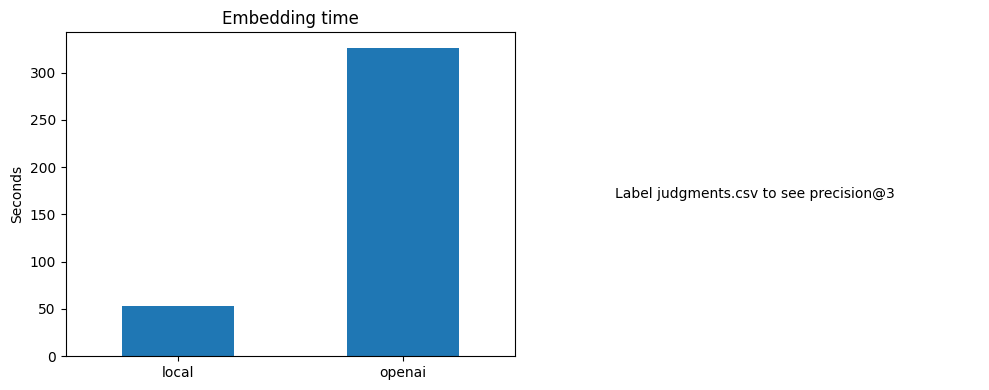

Saved configuration: c:\Users\ashym\Documents\GitHub\jarvis_data_eng_YashMehrotra\ml_3\reports\embedding_vectordb\retrieval_config.json


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
embedding_summary['seconds'].astype(float).plot.bar(ax=axes[0], rot=0)
axes[0].set(title='Embedding time', xlabel='', ylabel='Seconds')
if precision['questions scored'].max() > 0:
    precision['precision@3'].unstack().plot.bar(ax=axes[1], rot=0, ylim=(0, 1))
    axes[1].set(title='Precision@3', xlabel='', ylabel='Precision')
else:
    axes[1].set_axis_off()
    axes[1].text(0.5, 0.5, 'Label judgments.csv to see precision@3',
                 ha='center', va='center')
fig.tight_layout()
fig.savefig(REPORTS / 'model_comparison.png', dpi=150)
plt.show()

config = {
    'chroma_path': str(MODELS / 'chroma'),
    'collections': {label: collection.name for label, collection in collections.items()},
    'models': {label: model_name for label, (model_name, _) in embedders.items()},
    'default_provider': 'local',
    'top_k': TOP_K, 'fetch_k': FETCH_K, 'mmr_lambda': MMR_LAMBDA,
    'local_window_tokens': LOCAL_WINDOW_TOKENS,
}
(REPORTS / 'retrieval_config.json').write_text(json.dumps(config, indent=2), encoding='utf-8')
print('Saved configuration:', REPORTS / 'retrieval_config.json')